# **Student Performance Prediction and Academic Risk Analysis**

**Problem Statement:**
An academic department wants to identify students who may need additional academic support. You are given student
study habits, attendance, scores, previous GPA, and learning support information. Our task is to analyze the data,
predict final performance, classify academic risk level, and suggest simple support strategies.

In [65]:
# # upload dataset file

from google.colab import files
uploaded = files.upload()


In [66]:
# import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## **Part A: Data Loading and Understanding**

In [67]:
# 5. Load the dataset and display the first 10 rows.
df = pd.read_csv('student_performance_project_dataset.csv')
df.head(10)

,StudentID,Gender,StudyHoursPerWeek,AttendancePercent,AssignmentScore,QuizAverage,PreviousGPA,SleepHours,InternetAccess,ExtraClasses,ParentEducation,ProjectScore,FinalScore,PassStatus,RiskLevel
0,S2000,Male,12.1,82.0,86.8,76.5,8.73,5.5,Good,No,School,83.8,73.1,Pass,Low Risk
1,S2001,Female,10.3,95.9,91.7,84.6,7.80,6.2,Good,Yes,Graduate,77.6,78.2,Pass,Low Risk
2,S2002,Male,11.9,84.4,82.9,78.3,5.94,4.6,Average,No,School,59.6,63.9,Pass,Medium Risk
3,S2003,Female,4.4,62.3,71.2,94.8,7.01,7.3,Poor,No,Graduate,78.9,59.6,Pass,Medium Risk
4,S2004,Male,3.1,94.7,88.5,76.1,6.90,8.0,Average,No,Graduate,77.0,63.7,Pass,Medium Risk
5,S2005,Female,19.9,87.4,91.3,89.0,7.36,7.6,Poor,No,School,68.7,67.5,Pass,Low Risk
6,S2006,Female,15.5,100.0,95.6,79.1,8.03,7.5,Average,Yes,School,92.7,84.0,Pass,Low Risk
7,S2007,Female,1.0,61.9,81.6,62.1,7.73,7.5,Poor,No,School,68.5,55.3,Pass,Medium Risk
8,S2008,Male,9.8,82.4,88.6,83.0,7.86,7.4,Good,No,School,82.6,71.2,Pass,Low Risk
9,S2009,Male,17.8,94.8,99.0,99.9,7.91,7.3,Good,No,Graduate,94.4,82.5,Pass,Low Risk


In [68]:
# 6. Print dataset shape, column names, data types, and missing value count.
# dataset shape
print("Dataset shape:", df.shape)
print("="*50)

# column names
print("Column names:", df.columns.tolist())
print("="*50)

# data types
print("Data Types:\n", df.dtypes)
print("="*50)

# missing value count
print("Missing Values:\n", df.isnull().sum())



Dataset shape: (700, 15)
Column names: ['StudentID', 'Gender', 'StudyHoursPerWeek', 'AttendancePercent', 'AssignmentScore', 'QuizAverage', 'PreviousGPA', 'SleepHours', 'InternetAccess', 'ExtraClasses', 'ParentEducation', 'ProjectScore', 'FinalScore', 'PassStatus', 'RiskLevel']
Data Types:
 StudentID             object
Gender                object
StudyHoursPerWeek    float64
AttendancePercent    float64
AssignmentScore      float64
QuizAverage          float64
PreviousGPA          float64
SleepHours           float64
InternetAccess        object
ExtraClasses          object
ParentEducation       object
ProjectScore         float64
FinalScore           float64
PassStatus            object
RiskLevel             object
dtype: object
Missing Values:
 StudentID            0
Gender               0
StudyHoursPerWeek    0
AttendancePercent    0
AssignmentScore      0
QuizAverage          0
PreviousGPA          5
SleepHours           7
InternetAccess       6
ExtraClasses         0
ParentEducati

In [69]:
# 7. Find summary statistics for all numerical columns.

df.describe().T

,count,mean,std,min,25%,50%,75%,max
StudyHoursPerWeek,700.0,13.147714,5.517065,1.0,9.300,13.05,16.625,30.6
AttendancePercent,700.0,86.068000,10.881478,52.4,79.300,86.90,95.100,100.0
AssignmentScore,700.0,86.581714,11.332618,45.9,78.750,88.30,96.625,100.0
QuizAverage,700.0,81.812429,13.794895,42.5,72.175,83.35,93.325,100.0
PreviousGPA,695.0,7.435942,1.161586,3.5,6.625,7.44,8.255,10.0
SleepHours,693.0,6.746609,1.139189,3.5,5.900,6.70,7.500,9.5
ProjectScore,700.0,78.594571,11.896182,42.7,70.400,79.30,87.100,100.0
FinalScore,700.0,70.430714,7.823371,49.5,65.100,70.30,75.725,97.7


In [70]:
# 8. Count students in each PassStatus and RiskLevel category.

print(df['PassStatus'].value_counts())
print(df['RiskLevel'].value_counts())

PassStatus
Pass    698
Fail      2
Name: count, dtype: int64
RiskLevel
Low Risk       533
Medium Risk    167
Name: count, dtype: int64


In [71]:
# 9. Identify which features appear most related to FinalScore.
numerical_columns = df.select_dtypes(include=np.number).columns

df[numerical_columns].corr()

,StudyHoursPerWeek,AttendancePercent,AssignmentScore,QuizAverage,PreviousGPA,SleepHours,ProjectScore,FinalScore
StudyHoursPerWeek,1.000000,0.191973,0.308566,0.325358,0.108379,-0.022641,0.170824,0.650404
AttendancePercent,0.191973,1.000000,0.097842,0.066243,0.036088,0.071995,0.065813,0.300366
AssignmentScore,0.308566,0.097842,1.000000,0.127847,0.036103,-0.001837,0.086431,0.448737
QuizAverage,0.325358,0.066243,0.127847,1.000000,0.038932,0.031716,0.055280,0.446901
PreviousGPA,0.108379,0.036088,0.036103,0.038932,1.000000,-0.022579,0.041702,0.408001
SleepHours,-0.022641,0.071995,-0.001837,0.031716,-0.022579,1.000000,0.030032,0.056468
ProjectScore,0.170824,0.065813,0.086431,0.055280,0.041702,0.030032,1.000000,0.328633
FinalScore,0.650404,0.300366,0.448737,0.446901,0.408001,0.056468,0.328633,1.000000


StudyHoursPerWeek has the highest correlation with FinalScore of approximately 0.65.

## **Part B: Probability and Basic Analysis**

In [72]:
# 10. Find the probability that a randomly selected student passes.

total_students = len(df)
pass_count = (df['PassStatus'] == 'Pass').sum()

prob_pass = pass_count / total_students

print("Total students:", total_students)
print("Students who passed:", pass_count)
print("Probability of passing (%):", prob_pass * 100)

Total students: 700
Students who passed: 698
Probability of passing (%): 99.71428571428571


In [73]:
# 11. Find the probability that a student is in the High Risk category.

high_risk_count = (df['RiskLevel'] == 'High Risk').sum()

prob_high_risk = high_risk_count / total_students

print("High Risk students:", high_risk_count)
print("Probability of High Risk (%):", prob_high_risk * 100)

High Risk students: 0
Probability of High Risk (%): 0.0


In [74]:
# 12. Find the probability that AttendancePercent is greater than 75%.

attendance_above_75 = (df['AttendancePercent'] > 75).sum()

prob_attendance_above_75 = attendance_above_75 / total_students

print("Students with attendance > 75%:", attendance_above_75)
print("Probability (%):", prob_attendance_above_75 * 100)

Students with attendance > 75%: 590
Probability (%): 84.28571428571429


In [75]:
# 13. Find the probability that StudyHoursPerWeek is above the dataset mean.

mean_study_hours = df['StudyHoursPerWeek'].mean()

print("Mean StudyHoursPerWeek:", mean_study_hours)

study_above_mean = (df['StudyHoursPerWeek'] > mean_study_hours).sum()

prob_study_above_mean = study_above_mean / total_students

print("Students above mean study hours:", study_above_mean)
print("Probability (%):", prob_study_above_mean * 100)

Mean StudyHoursPerWeek: 13.147714285714285
Students above mean study hours: 347
Probability (%): 49.57142857142857


In [76]:
# 14. Compare pass probability for students with and without ExtraClasses.

# Students with extra classes
extra_yes = df[df['ExtraClasses'] == 'Yes']
passed_yes = extra_yes[extra_yes['PassStatus'] == 'Pass']

# Students without extra classes
extra_no = df[df['ExtraClasses'] == 'No']
passed_no = extra_no[extra_no['PassStatus'] == 'Pass']

# Probabilities
prob_yes = len(passed_yes) / len(extra_yes)
prob_no = len(passed_no) / len(extra_no)

print("WITH Extra Classes:")
print("Total students:", len(extra_yes))
print("Passed students:", len(passed_yes))
print("Pass probability (%):", prob_yes * 100)

print("\nWITHOUT Extra Classes:")
print("Total students:", len(extra_no))
print("Passed students:", len(passed_no))
print("Pass probability (%):", prob_no * 100)

WITH Extra Classes:
Total students: 260
Passed students: 260
Pass probability (%): 100.0

WITHOUT Extra Classes:
Total students: 440
Passed students: 438
Pass probability (%): 99.54545454545455


## **Part C: Exploratory Data Analysis and Visualization**

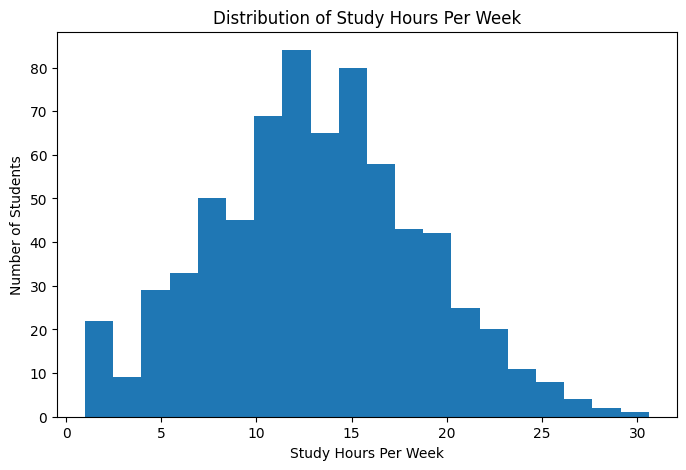

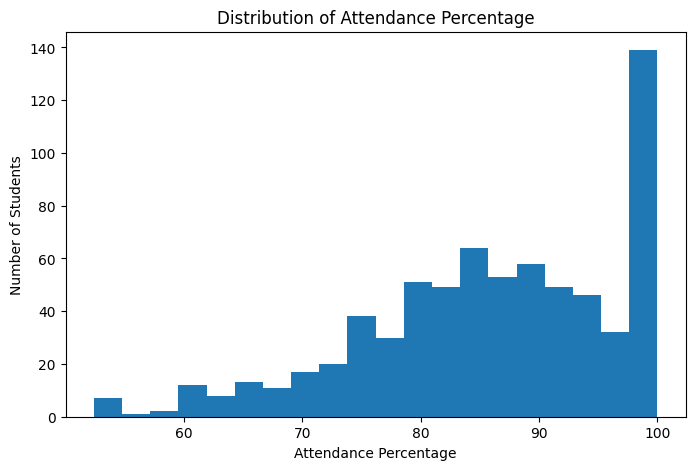

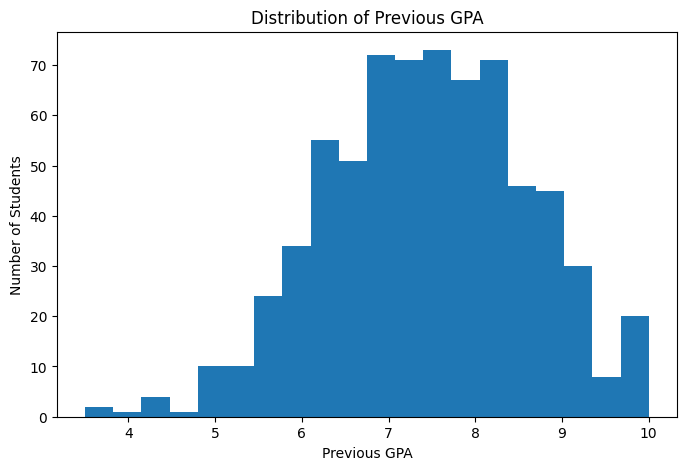

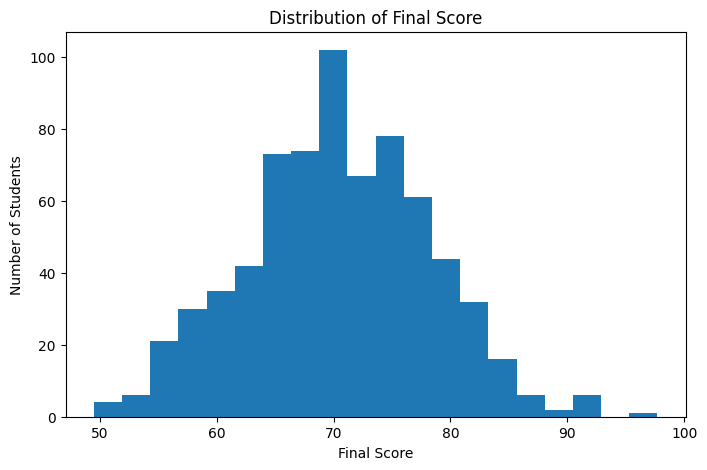

In [77]:
# 15. Plot histograms for StudyHoursPerWeek, AttendancePercent, PreviousGPA, and FinalScore.

# StudyHoursPerWeek
plt.figure(figsize=(8, 5))

plt.hist(df['StudyHoursPerWeek'], bins=20)

plt.title('Distribution of Study Hours Per Week')
plt.xlabel('Study Hours Per Week')
plt.ylabel('Number of Students')

plt.show()

# AttendancePercent, PreviousGPA, and FinalScore
plt.figure(figsize=(8, 5))

plt.hist(df['AttendancePercent'], bins=20)

plt.title('Distribution of Attendance Percentage')
plt.xlabel('Attendance Percentage')
plt.ylabel('Number of Students')

plt.show()

# PreviousGPA
plt.figure(figsize=(8, 5))

plt.hist(df['PreviousGPA'], bins=20)

plt.title('Distribution of Previous GPA')
plt.xlabel('Previous GPA')
plt.ylabel('Number of Students')

plt.show()

# FinalScore
plt.figure(figsize=(8, 5))

plt.hist(df['FinalScore'], bins=20)

plt.title('Distribution of Final Score')
plt.xlabel('Final Score')
plt.ylabel('Number of Students')

plt.show()

<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

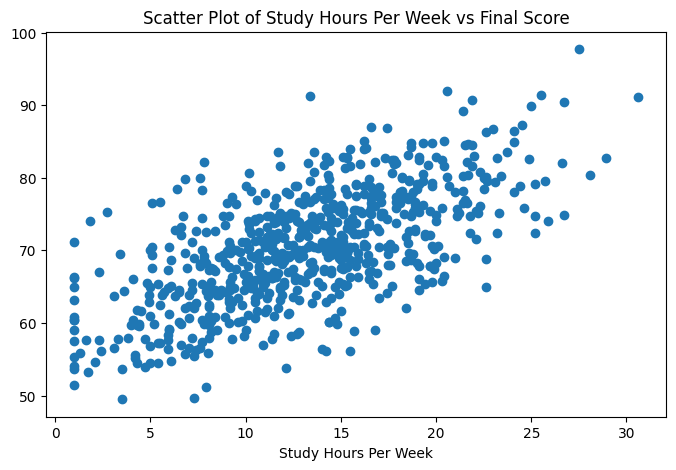

In [78]:
# 16. Create a scatter plot of StudyHoursPerWeek vs FinalScore.

plt.figure(figsize=(8, 5))

plt.scatter(df['StudyHoursPerWeek'], df['FinalScore'])

plt.title('Scatter Plot of Study Hours Per Week vs Final Score')
plt.xlabel('Study Hours Per Week')
plt

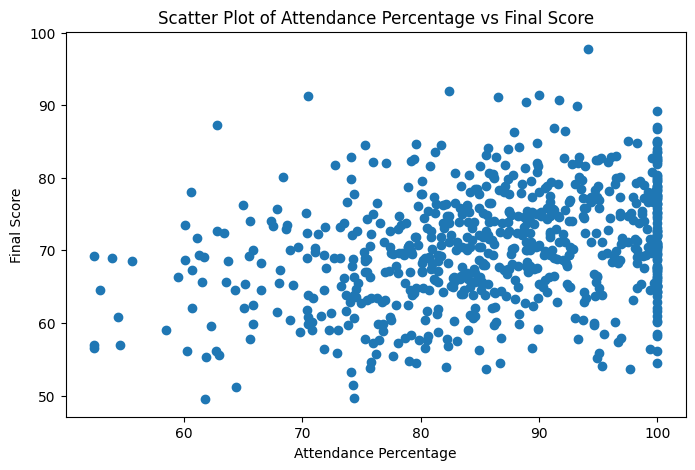

In [79]:
# 17. Create a scatter plot of AttendancePercent vs FinalScore.

plt.figure(figsize=(8, 5))

plt.scatter(df['AttendancePercent'], df['FinalScore'])

plt.title('Scatter Plot of Attendance Percentage vs Final Score')
plt.xlabel('Attendance Percentage')
plt.ylabel('Final Score')

plt.show()

Text(0, 0.5, 'Final Score')

<Figure size 800x500 with 0 Axes>

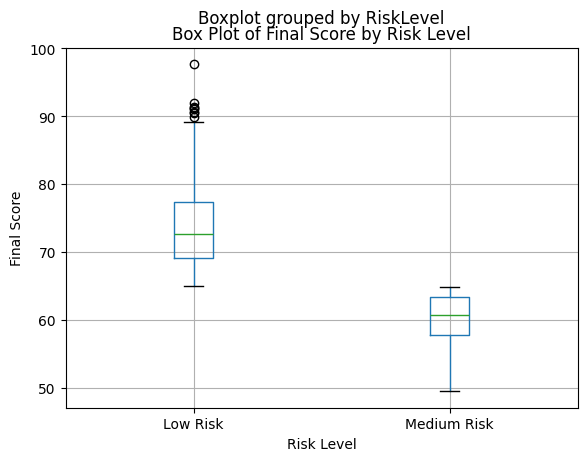

In [80]:
# 18. Create a box plot of FinalScore grouped by RiskLevel.

plt.figure(figsize=(8, 5))

df.boxplot(column='FinalScore', by='RiskLevel')

plt.title('Box Plot of Final Score by Risk Level')
plt.xlabel('Risk Level')
plt.ylabel('Final Score')

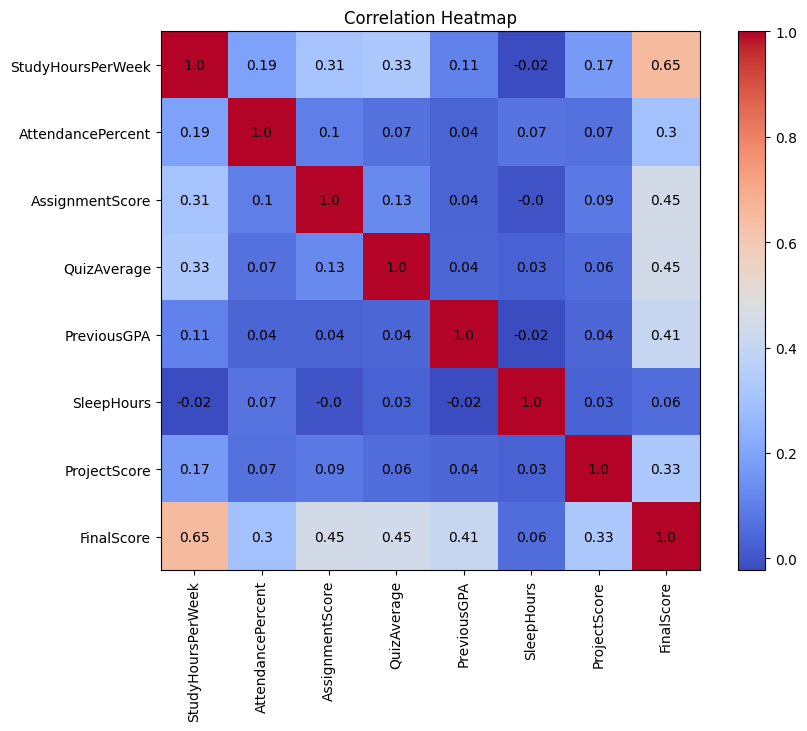

In [81]:
# 19. Create a correlation heatmap and write 5 observations.

correlation_matrix = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(10, 7))

plt.imshow(correlation_matrix, cmap='coolwarm', interpolation='none')

plt.colorbar()

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j,
            i,
            round(correlation_matrix.iloc[i, j], 2),
            ha='center',
            va='center'
        )

plt.title('Correlation Heatmap')

plt.show()

**5 heatmap observations:**

1. StudyHoursPerWeek has the strongest positive correlation with FinalScore, approximately 0.65.
2. AssignmentScore and QuizAverage have moderate positive relationships with FinalScore, with correlations of approximately 0.45 and 0.45.
3. PreviousGPA has a moderate positive relationship with FinalScore, with a correlation of approximately 0.41.
4. AttendancePercent has a positive but weaker relationship with FinalScore, with a correlation of 0.30.
5. SleepHours has almost no linear relationship with FinalScore, with a correlation of approximately 0.06.

## **Part D-1: Data Preprocessing (For Regression)**

In [82]:
# 23-A. Create target variable: FinalScore for regression

# Target variable
y = df['FinalScore']

# Predictor variables
X = df.drop(columns=[
    'StudentID',   #as this is a unique identifier
    'FinalScore'

])

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

X shape: (700, 13)
y shape: (700,)

Features:
['Gender', 'StudyHoursPerWeek', 'AttendancePercent', 'AssignmentScore', 'QuizAverage', 'PreviousGPA', 'SleepHours', 'InternetAccess', 'ExtraClasses', 'ParentEducation', 'ProjectScore', 'PassStatus', 'RiskLevel']


In [83]:
# 24. Split data into training and testing sets.
from sklearn.model_selection import train_test_split

# Did Train-Test Split before data preprocessing to avoid DATA LEAKAGE
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training data: (560, 13)
Testing data: (140, 13)
Training target: (560,)
Testing target: (140,)


In [84]:
# 20. Separate numerical and categorical columns.
numerical_features = [
    'StudyHoursPerWeek',
    'AttendancePercent',
    'AssignmentScore',
    'QuizAverage',
    'PreviousGPA',
    'SleepHours',
    'ProjectScore'
]

categorical_features = [
    'Gender',
    'InternetAccess',
    'ExtraClasses',
    'ParentEducation',
    'PassStatus',
    'RiskLevel'
]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['StudyHoursPerWeek', 'AttendancePercent', 'AssignmentScore', 'QuizAverage', 'PreviousGPA', 'SleepHours', 'ProjectScore']

Categorical features:
['Gender', 'InternetAccess', 'ExtraClasses', 'ParentEducation', 'PassStatus', 'RiskLevel']


In [85]:
# 21. Encode categorical features (Gender, InternetAccess, ExtraClasses, ParentEducation, PassStatus, RiskLevel).
# 22. Scale numerical features using StandardScaler.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, OneHotEncoder, OrdinalEncoder)

# numerical column preprocessing
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Binary categorical column preprocessing- used one hot encoder
binary_features = [
    'Gender',
    'ExtraClasses',
    'PassStatus',
    'RiskLevel'
]

binary_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        drop='first',
        handle_unknown='ignore',
        sparse_output=False
    ))
])


# InternetAccess preprocessing- used one hot encoder
internet_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        drop='first',
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# ParentEducation preprocessing- used ordinal encoder
parent_education_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        categories=[
            ['School', 'Graduate', 'Postgraduate']
        ]
    ))
])

# combined preprocessor

preprocessor = ColumnTransformer([
    ('numerical', numerical_pipeline, numerical_features),
    ('binary', binary_pipeline, binary_features),
    ('internet', internet_pipeline, ['InternetAccess']),
    ('parent_education', parent_education_pipeline, ['ParentEducation'])
])


## **Part E: Regression Task - Predict Final Score**

**Model 1-Linear Regression**

In [86]:
from sklearn.linear_model import LinearRegression

# Linear Regression Pipeline
linear_regression_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', LinearRegression())
])

# model fit
linear_regression_pipeline.fit(X_train, y_train)

# model predict
y_pred_linear = linear_regression_pipeline.predict(X_test)

comparison = pd.DataFrame({
    'Actual FinalScore': y_test.values,
    'Predicted FinalScore': y_pred_linear
})

comparison.head(10)

,Actual FinalScore,Predicted FinalScore
0,72.7,72.892935
1,67.3,72.035426
2,71.4,71.590977
3,70.2,72.723335
4,66.4,64.698748
5,77.5,76.387748
6,59.8,61.949277
7,75.2,78.341064
8,70.3,71.038899
9,72.4,66.456643


In [87]:
# 26. Evaluate using MAE, MSE, RMSE, and R2 score for Linear Regression.

from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

mae_linear = mean_absolute_error(y_test, y_pred_linear)

mse_linear = mean_squared_error(y_test, y_pred_linear)

rmse_linear = np.sqrt(mse_linear)

r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression")
print("="*25)
print("MAE :", mae_linear)
print("MSE :", mse_linear)
print("RMSE:", rmse_linear)
print("R²  :", r2_linear)
print("="*25)


Linear Regression
MAE : 2.9286079772772786
MSE : 13.089525643951246
RMSE: 3.6179449476120067
R²  : 0.7530036510104392


**Model 2- Decision Tree Regressor**

In [88]:
# Decision Tree Regressor
from sklearn.tree import DecisionTreeRegressor

decision_tree_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', DecisionTreeRegressor(random_state=42))
])

decision_tree_pipeline.fit(X_train, y_train)

y_pred_tree = decision_tree_pipeline.predict(X_test)


# Evaluation
mae_tree = mean_absolute_error(y_test, y_pred_tree)

mse_tree = mean_squared_error(y_test, y_pred_tree)

rmse_tree = np.sqrt(mse_tree)

r2_tree = r2_score(y_test, y_pred_tree)

print("Decision Tree Regressor")
print("="*25)
print("MAE :", mae_tree)
print("MSE :", mse_tree)
print("RMSE:", rmse_tree)
print("R²  :", r2_tree)
print("="*25)

Decision Tree Regressor
MAE : 4.484285714285713
MSE : 33.20057142857142
RMSE: 5.7619937025799866
R²  : 0.37351282618757586


**Model 3- Random Forest Regressor**

In [89]:
from sklearn.ensemble import RandomForestRegressor

# Random Forest
random_forest_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=150,
        random_state=42

    ))
])

random_forest_pipeline.fit(X_train, y_train)

y_pred_rf = random_forest_pipeline.predict(X_test)

# Evaluation

mae_rf = mean_absolute_error(y_test, y_pred_rf)

mse_rf = mean_squared_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(mse_rf)

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Regressor")
print("="*25)
print("MAE :", mae_rf)
print("MSE :", mse_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)
print("="*25)

Random Forest Regressor
MAE : 3.2258999999999975
MSE : 15.715237038095218
RMSE: 3.964244825700756
R²  : 0.7034570787743746


**Compare all three models**

In [90]:
regression_results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'MAE': [
        mae_linear,
        mae_tree,
        mae_rf
    ],
    'MSE': [
        mse_linear,
        mse_tree,
        mse_rf
    ],
    'RMSE': [
        rmse_linear,
        rmse_tree,
        rmse_rf
    ],
    'R2': [
        r2_linear,
        r2_tree,
        r2_rf
    ]
})

regression_results

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,2.928608,13.089526,3.617945,0.753004
1,Decision Tree,4.484286,33.200571,5.761994,0.373513
2,Random Forest,3.225900,15.715237,3.964245,0.703457


**Best Model:** Linear Regression is the best model because it has the lowest MAE, MSE, RMSE and the highest R².

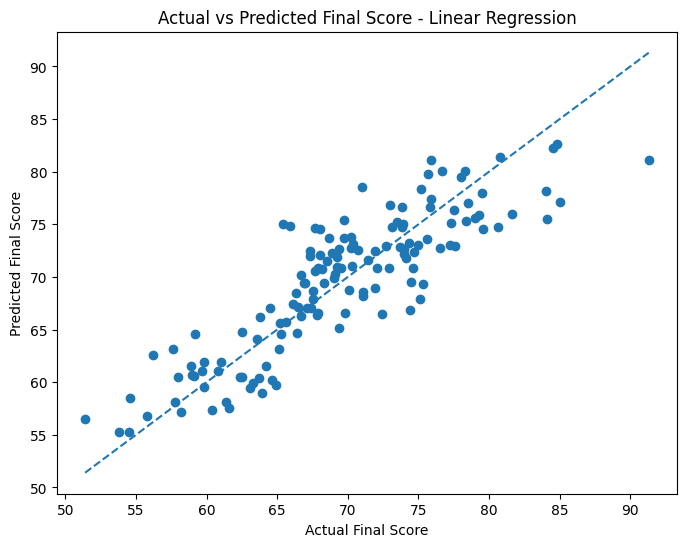

In [91]:
# 27. Plot actual vs predicted FinalScore for the best model(Regression).

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_linear)

# Reference line: perfect prediction
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel('Actual Final Score')
plt.ylabel('Predicted Final Score')
plt.title('Actual vs Predicted Final Score - Linear Regression')

plt.show()

In [92]:
# 28. Identify which features help predict FinalScore.

feature_names = (
    linear_regression_pipeline
    .named_steps['preprocessing']
    .get_feature_names_out()
)

coefficients = (
    linear_regression_pipeline
    .named_steps['model']
    .coef_
)

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

feature_importance = feature_importance.sort_values(
    by='Coefficient',
    ascending=False
)

feature_importance

,Feature,Coefficient
9,binary__PassStatus_Pass,4.163191
0,numerical__StudyHoursPerWeek,2.534660
4,numerical__PreviousGPA,2.242032
8,binary__ExtraClasses_Yes,2.231308
3,numerical__QuizAverage,1.669900
11,internet__InternetAccess_Good,1.604290
2,numerical__AssignmentScore,1.555550
6,numerical__ProjectScore,0.925818
1,numerical__AttendancePercent,0.803660
5,numerical__SleepHours,0.414124


**Predictor Analysis Based on Linear Regression Coefficients:**
1. RiskLevel and PassStatus have the largest coefficient magnitudes, indicating strong associations with predicted FinalScore.
2. StudyHoursPerWeek also has a strong relationship, indicating that higher study hours are associated with a higher predicted FinalScore.
3. PreviousGPA and ExtraClasses also have positive coefficients, suggesting that higher previous GPA and taking extra classes are associated with higher predicted FinalScore.
4. QuizAverage and AssignmentScore have positive coefficients, indicating positive relationships with predicted FinalScore.
5. Attendance and ProjectScore have moderate positive effects
6. Compared with the reference category (Average), Good InternetAccess is related to a higher predicted FinalScore, while Poor InternetAccess is associated with a lower predicted FinalScore.

**Short Explanation:** The Linear Regression model's MAE of 2.92 and RMSE of 3.61, indicates that the predicted FinalScore values are generally close to the actual values. The R-square score of 0.75 indicates that the model explains 75% of the variation in FinalScore.

## **Part D-2: Data Preprocessing (For Classification)**

**PassStatus** and **FinalScore** were initially included in the features. But they lead to target leakage as they are highly correlated with the target. Due to this the accuracy and other metrics shows 100% results. No missclassification whatsoever. So FinalScore was excluded from the indeoendent variables.

In [93]:
# 23-B. Create target variable: FinalScore for classification

# Classification target
y_class = df['RiskLevel']

# Classification features
X_class = df.drop(columns=[
    'StudentID',
    'FinalScore',
    'RiskLevel'
])

print("X_class shape:", X_class.shape)
print("y_class shape:", y_class.shape)

print("\nClassification features:")
print(X_class.columns.tolist())

X_class shape: (700, 12)
y_class shape: (700,)

Classification features:
['Gender', 'StudyHoursPerWeek', 'AttendancePercent', 'AssignmentScore', 'QuizAverage', 'PreviousGPA', 'SleepHours', 'InternetAccess', 'ExtraClasses', 'ParentEducation', 'ProjectScore', 'PassStatus']


In [94]:
# Split data into training and testing sets.
from sklearn.model_selection import train_test_split

X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

print("Training data:", X_class_train.shape)
print("Testing data:", X_class_test.shape)



Training data: (560, 12)
Testing data: (140, 12)


In [95]:
# Target Encoding

y_class_train = y_class_train.map({
    'Low Risk': 0,
    'Medium Risk': 1
})

y_class_test = y_class_test.map({
    'Low Risk': 0,
    'Medium Risk': 1
})



In [96]:
# define features

numerical_features = [
    'StudyHoursPerWeek',
    'AttendancePercent',
    'AssignmentScore',
    'QuizAverage',
    'PreviousGPA',
    'SleepHours',
    'ProjectScore'

]

binary_features = [
    'Gender',
    'ExtraClasses',
    'PassStatus',

]

internet_features = [
    'InternetAccess'
]

parent_education_features = [
    'ParentEducation'
]

In [97]:
# preprocessing

numerical_pipeline_class = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

binary_pipeline_class = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        drop='first',
        handle_unknown='ignore',
        sparse_output=False
    ))
])

internet_pipeline_class = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        drop='first',
        handle_unknown='ignore',
        sparse_output=False
    ))
])

parent_education_pipeline_class = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        categories=[
            ['School', 'Graduate', 'Postgraduate']
        ]
    ))
])

In [98]:
# combine preprocessing

preprocessor_class = ColumnTransformer([
    (
        'numerical',
        numerical_pipeline_class,
        numerical_features
    ),
    (
        'binary',
        binary_pipeline_class,
        binary_features
    ),
    (
        'internet',
        internet_pipeline_class,
        internet_features
    ),
    (
        'parent_education',
        parent_education_pipeline_class,
        parent_education_features
    )
])

## **Part F: Classification Task - Predict Risk Level**

**Model 1- Logistic Regression**

In [99]:
# Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix)

logistic_pipeline = Pipeline([
    ('preprocessing', preprocessor_class),
    ('model', LogisticRegression(random_state=42, class_weight='balanced'))
])

logistic_pipeline.fit(X_class_train, y_class_train)
y_class_train_pred = logistic_pipeline.predict(X_class_train)
y_class_pred_logistic = logistic_pipeline.predict(X_class_test)



# Evaluation
accuracy_train = accuracy_score(y_class_train, y_class_train_pred)

accuracy_logistic = accuracy_score(y_class_test, y_class_pred_logistic)

precision_logistic = precision_score(y_class_test, y_class_pred_logistic)

recall_logistic = recall_score(y_class_test, y_class_pred_logistic)

f1_logistic = f1_score(y_class_test, y_class_pred_logistic)

cm_logistic = confusion_matrix(y_class_test, y_class_pred_logistic)


print("Logistic Regression")
print("="*25)
print("Accuracy Train:", accuracy_train)
print("Accuracy Test:", accuracy_logistic)
print("Precision:", precision_logistic)
print("Recall   :", recall_logistic)
print("F1 Score :", f1_logistic)
print("="*25)
print(cm_logistic)



Logistic Regression
Accuracy Train: 0.8625
Accuracy Test: 0.8714285714285714
Precision: 0.6595744680851063
Recall   : 0.9393939393939394
F1 Score : 0.775
[[91 16]
 [ 2 31]]


**Model 2- Decision Tree Classifier**

In [100]:
# Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier

decision_tree_class_pipeline = Pipeline([
    ('preprocessing', preprocessor_class),
    ('model', DecisionTreeClassifier(random_state=42))
])

decision_tree_class_pipeline.fit(X_class_train, y_class_train)

y_class_pred_tree = decision_tree_class_pipeline.predict(X_class_test)


accuracy_tree_class = accuracy_score(y_class_test, y_class_pred_tree)

precision_tree_class = precision_score(y_class_test, y_class_pred_tree)

recall_tree_class = recall_score(y_class_test, y_class_pred_tree)

f1_tree_class = f1_score(y_class_test, y_class_pred_tree)

cm_tree = confusion_matrix(y_class_test, y_class_pred_tree)


print("Decision Tree")
print("="*25)
print("Accuracy :", accuracy_tree_class)
print("Precision:", precision_tree_class)
print("Recall   :", recall_tree_class)
print("F1 Score :", f1_tree_class)
print("="*25)
print(cm_tree)

Decision Tree
Accuracy : 0.8142857142857143
Precision: 0.5777777777777777
Recall   : 0.7878787878787878
F1 Score : 0.6666666666666666
[[88 19]
 [ 7 26]]


**Model 3- Random Forest Classifier**

In [101]:
# Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

random_forest_class_pipeline = Pipeline([
    ('preprocessing', preprocessor_class),
    ('model', RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight='balanced'
    ))
])


random_forest_class_pipeline.fit(X_class_train, y_class_train)

y_class_pred_rf = random_forest_class_pipeline.predict(X_class_test)


# Evaluation
accuracy_rf_class = accuracy_score(y_class_test, y_class_pred_rf)

precision_rf_class = precision_score(y_class_test, y_class_pred_rf)

recall_rf_class = recall_score(y_class_test, y_class_pred_rf)

f1_rf_class = f1_score(y_class_test, y_class_pred_rf)

cm_rf_class = confusion_matrix(y_class_test, y_class_pred_rf)



print("Random Forest")
print("="*25)
print("Accuracy :", accuracy_rf_class)
print("Precision:", precision_rf_class)
print("Recall   :", recall_rf_class)
print("F1 Score :", f1_rf_class)
print("="*25)
print(cm_rf_class)

Random Forest
Accuracy : 0.8928571428571429
Precision: 0.8461538461538461
Recall   : 0.6666666666666666
F1 Score : 0.7457627118644068
[[103   4]
 [ 11  22]]


In [102]:
# 32. Compare models in a table.

classification_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_logistic,
        accuracy_tree_class,
        accuracy_rf_class
    ],
    'Precision': [
        precision_logistic,
        precision_tree_class,
        precision_rf_class
    ],
    'Recall': [
        recall_logistic,
        recall_tree_class,
        recall_rf_class
    ],
    'F1 Score': [
        f1_logistic,
        f1_tree_class,
        f1_rf_class
    ]
})

classification_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.871429,0.659574,0.939394,0.775000
1,Decision Tree,0.814286,0.577778,0.787879,0.666667
2,Random Forest,0.892857,0.846154,0.666667,0.745763


**33. Explain which model is best for identifying students who need support.**
I would select Logistic Regression as the best model. The reason is that our objective is not simply to achieve the highest overall accuracy. We want to identify students who may need academic support, which means we want to avoid missing actual Medium Risk students. Logistic Regression has the highest recall (93.94%) for Medium Risk students and the highest F1-score (77.50%). Minimizing false negatives is here more important than maximizing overall accuracy.

**34. Discuss whether accuracy alone is enough for this problem.**
No. Accuracy alone is not enough. The dataset contains more Low Risk students than Medium Risk students, so a model can achieve relatively high accuracy and also can fail to identify some Medium Risk students. Since the objective of the model is to identify students who may need academic support, recall is very important because it measures how many actual Medium Risk students are correctly identified. Precision is also useful.

## **Part G: Neural Network**

In [103]:
# train an MLPClassifier/MLPRegressor using scikit-learn.

from sklearn.neural_network import MLPRegressor

mlp_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        learning_rate_init=0.001,
        max_iter=2000,
        early_stopping=True,
        validation_fraction=0.2,
        n_iter_no_change=30,
        random_state=42
    ))
])

mlp_pipeline.fit(X_train, y_train)

y_pred_mlp = mlp_pipeline.predict(X_test)


# Evaluation
mae_mlp = mean_absolute_error(
    y_test,
    y_pred_mlp
)

mse_mlp = mean_squared_error(
    y_test,
    y_pred_mlp
)

rmse_mlp = np.sqrt(mse_mlp)

r2_mlp = r2_score(
    y_test,
    y_pred_mlp
)

print("MLPRegressor")
print("MAE :", mae_mlp)
print("MSE :", mse_mlp)
print("RMSE:", rmse_mlp)
print("R²  :", r2_mlp)


MLPRegressor
MAE : 3.4390182282777606
MSE : 17.937564160180138
RMSE: 4.235276161028952
R²  : 0.6615222753027831


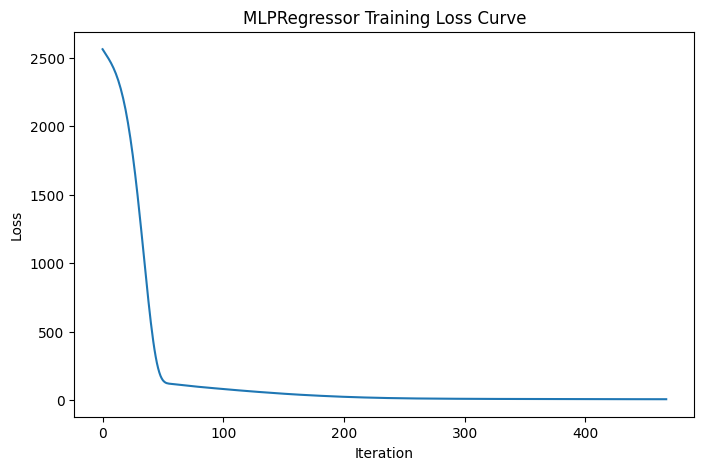

In [104]:
# 36. Plot the loss curve or training performance curve.
plt.figure(figsize=(8, 5))

plt.plot(
    mlp_pipeline.named_steps['model'].loss_curve_
)

plt.title('MLPRegressor Training Loss Curve')
plt.xlabel('Iteration')
plt.ylabel('Loss')

plt.show()

In [105]:
# 37. Compare the neural network with linear regression.

mlp_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'MLPRegressor'
    ],
    'MAE': [
        mae_linear,
        mae_mlp
    ],
    'MSE': [
        mse_linear,
        mse_mlp
    ],
    'RMSE': [
        rmse_linear,
        rmse_mlp
    ],
    'R2': [
        r2_linear,
        r2_mlp
    ]
})

mlp_comparison

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,2.928608,13.089526,3.617945,0.753004
1,MLPRegressor,3.439018,17.937564,4.235276,0.661522


Linear Regression performed better than MLPRegressor on the test data. Linear Regression achieved an MAE of 2.92, RMSE of 3.61 and R² of 0.753, compared with an MAE of 3.43, RMSE of 4.23 and R² of 0.661 for the MLPRegressor.

**38. Explain why learning rate and iterations affect model performance.**

The learning rate determines the size of the weight updates during training. Very small learning rate can make training very slow, while a learning rate that is too large can cause unstable training or prevent the model from converging.

Iterations determine how many times the network updates its weights. Very few iterations may result in insufficient training, while increasing the number of iterations allows the model to reduce the training loss. Once the loss has converged, more number of iterations may cause little improvement.

## **Part H: Dimensionality Reduction**

In [106]:
# Transform all students using the preprocessing learned during classification

X_pca_prepared = preprocessor.fit_transform(X)
print("Shape after preprocessing:", X_pca_prepared.shape)

Shape after preprocessing: (700, 14)


In [107]:
# 39. Apply PCA and reduce data to 2 components.

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_pca_prepared)

print("PCA shape:", X_pca.shape)

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal variance explained:")
print(pca.explained_variance_ratio_.sum())

PCA shape: (700, 2)

Explained variance ratio:
[0.20569428 0.12318601]

Total variance explained:
0.32888029534212443


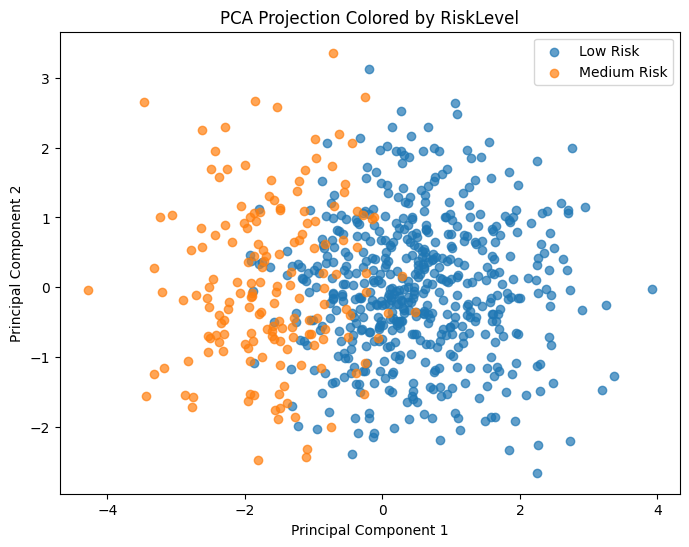

In [108]:
# 40. Plot PCA points colored by RiskLevel.

risk_level = df['RiskLevel']

plt.figure(figsize=(8, 6))

for risk in ['Low Risk', 'Medium Risk']:

    mask = risk_level == risk

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=risk,
        alpha=0.7
    )

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA Projection Colored by RiskLevel')
plt.legend()

plt.show()

PCA shows some separation between the Low Risk and Medium Risk groups, along PC1, but there is considerable overlap between the two groups. Thus, the 2 risk categories are not completely separable in the first two principal components.

In [109]:
# 41. Apply LDA for supervised dimensionality reduction if using RiskLevel as target.

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(n_components=1)

X_lda = lda.fit_transform(
    X_pca_prepared,
    risk_level
)

print("LDA shape:", X_lda.shape)

LDA shape: (700, 1)


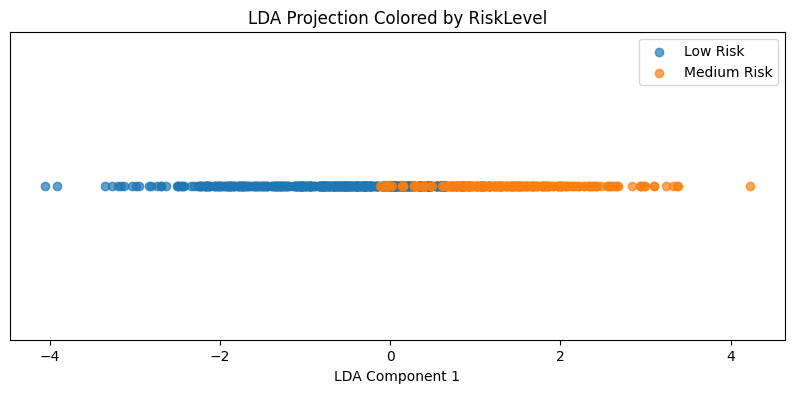

In [110]:
# Plot LDA

plt.figure(figsize=(10, 4))

for risk in ['Low Risk', 'Medium Risk']:

    mask = risk_level == risk

    plt.scatter(
        X_lda[mask, 0],
        np.zeros(mask.sum()),
        label=risk,
        alpha=0.7
    )

plt.xlabel('LDA Component 1')
plt.yticks([])
plt.title('LDA Projection Colored by RiskLevel')
plt.legend()

plt.show()

LDA produces a much more distinct division along its single component.

In [111]:
# 42. Apply t-SNE and compare with PCA.

from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=30,
    max_iter=1000,
    random_state=42
)

X_tsne = tsne.fit_transform(X_pca_prepared)

print("t-SNE shape:", X_tsne.shape)

t-SNE shape: (700, 2)


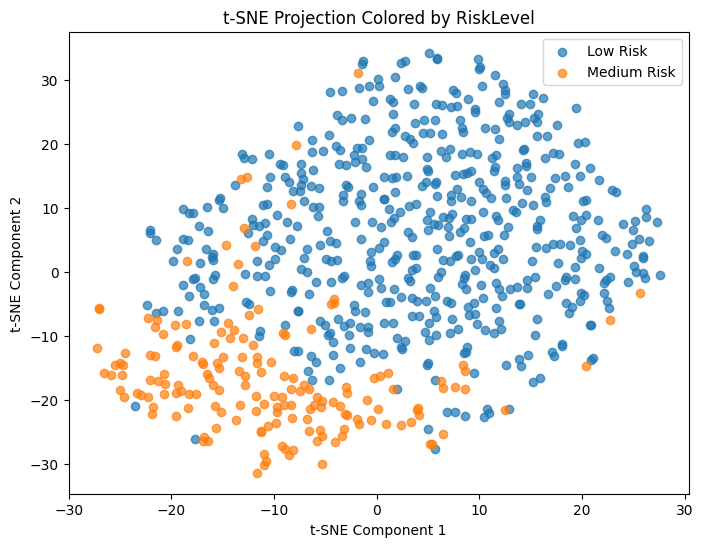

In [112]:
# t-SNE Plot

plt.figure(figsize=(8, 6))

for risk in ['Low Risk', 'Medium Risk']:

    mask = risk_level == risk

    plt.scatter(
        X_tsne[mask, 0],
        X_tsne[mask, 1],
        label=risk,
        alpha=0.7
    )

plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.title('t-SNE Projection Colored by RiskLevel')
plt.legend()

plt.show()

**43. Explain which method separates risk groups better.**

LDA shows the clearest separation between Low Risk and Medium Risk students. PCA shows some separation, but the two groups have substantial overlap. t-SNE provides better visual separation than PCA, but some overlap remains. LDA performs best because it is a supervised method that uses RiskLevel information when determining the projection and tries to maximize separation between the risk groups.